In [10]:
import geopandas as gpd
import pandas as pd
path_dane = "./dane/"


In [50]:
#GEOJSON WULKANY
path_wulkany = "./dane/wulkany/"
geojson_vulcan = gpd.read_file(path_wulkany+"lw1.geojson")
geojson_vulcan.head()


,gid,nazwa,ostatnia_erupcja,kraj,typ,rodzaj_erupcji,materiał,tektonika,legenda,źródło,geometry
0,830,Ambae,2021,Vanuatu,tarczowy,erupcja zaobserwowana,bazalt / pikryt,strefa subdukcji / skorupa oceaniczna (< 15 km),Wulkan,"Global Volcanism Program, 2013. Volcanoes of t...",POINT (167.835 -15.389)
1,499,Pavlof,2021,Stany Zjednoczone,stratowulkan,erupcja zaobserwowana,andezyt / andezyt bazaltowy,strefa subdukcji / skorupa kontynentalna (>25 km),Wulkan,"Global Volcanism Program, 2013. Volcanoes of t...",POINT (-161.894 55.417)
2,821,Kavachi,2021,Wyspy Salomona,podwodny,erupcja zaobserwowana,andezyt / andezyt bazaltowy,strefa subdukcji / grubość skorupy nieznana,Wulkan,"Global Volcanism Program, 2013. Volcanoes of t...",POINT (157.979 -8.991)
3,1130,Rincon de la Vieja,2021,Kostaryka,"mieszane, złożone",erupcja zaobserwowana,andezyt / andezyt bazaltowy,strefa subdukcji / skorupa kontynentalna (>25 km),Wulkan,"Global Volcanism Program, 2013. Volcanoes of t...",POINT (-85.324 10.83)
4,469,Great Sitkin,2021,Stany Zjednoczone,stratowulkan,erupcja zaobserwowana,andezyt / andezyt bazaltowy,strefa subdukcji / skorupa oceaniczna (< 15 km),Wulkan,"Global Volcanism Program, 2013. Volcanoes of t...",POINT (-176.13 52.076)


In [3]:
#GEOJSON RZEKI
rivers = gpd.read_file(path_dane + "hr1.geojson")
print(rivers.head())


   gid       nazwa  typ   długość                                     opis  \
0    3  North Fork  NaN       NaN  Opis zostanie dodany w następnej wersji   
1  152       Indus  NaN  3 180 km  Opis zostanie dodany w następnej wersji   
2  239  Rio Grande  NaN  3 051 km  Opis zostanie dodany w następnej wersji   
3  357   Missisipi  NaN  3 766 km  Opis zostanie dodany w następnej wersji   
4  505       Niger  NaN  4 184 km  Opis zostanie dodany w następnej wersji   

  legenda                                             źródło  \
0   rzeka  Made with Natural Earth (www.naturalearthdata....   
1   rzeka  Made with Natural Earth (www.naturalearthdata....   
2   rzeka  Made with Natural Earth (www.naturalearthdata....   
3   rzeka  Made with Natural Earth (www.naturalearthdata....   
4   rzeka  Made with Natural Earth (www.naturalearthdata....   

                                            geometry  
0  MULTILINESTRING ((-151.67419 64.30139, -151.67...  
1  MULTILINESTRING ((67.66363 24.106

In [4]:
#GEOJSON DEMOGRAFIA

demo = gpd.read_file(path_dane + "lsp1.geojson")
print(demo.head())

   gid       nazwa                                   źródło          legenda  \
0    1    Salwador  na podstawie https://data.worldbank.org  od 6,5% do 9,4%   
1    2    Honduras  na podstawie https://data.worldbank.org    od 4% do 6,5%   
2    3       Haiti  na podstawie https://data.worldbank.org    od 4% do 6,5%   
3    4  Kazachstan  na podstawie https://data.worldbank.org  od 6,5% do 9,4%   
4   12  Montserrat  na podstawie https://data.worldbank.org      brak danych   

  ludność_w_wieku_65_lat_i_więcej  \
0                          8.83 %   
1                          5.11 %   
2                          5.28 %   
3                          8.17 %   
4                     brak danych   

                                            geometry  
0  MULTIPOLYGON (((-89.95445 13.66398, -90 13.697...  
1  MULTIPOLYGON (((-86.62668 16.27028, -86.6339 1...  
2  MULTIPOLYGON (((-72.64029 19.98528, -72.6939 1...  
3  MULTIPOLYGON (((58.56551 45.56996, 58.56055 45...  
4  MULTIPOLYGON (((-6

In [46]:
#Dla warstwy z rzekami policz ile jest obiektów których MultiLineString zawiera dokładnie między 2 a 10 części składowych geometrii

rivers["ilosc"] = rivers.geometry.apply(lambda geom: len(geom.geoms))

rivers_multi = rivers[ (rivers["ilosc"] <= 10) & (rivers["ilosc"] >= 2) ]

print(len(rivers_multi))


250


In [16]:
#Dla warstwy demograficznej wyświetl na mapie kraje, w których odsetek osób w wieku 65+ wynosi ponad 18%


#selekcja i przygotowanie danych 

demo["ludnosc_65_percent"] = pd.to_numeric(
    demo["ludność_w_wieku_65_lat_i_więcej"]
    .astype(str)
    .str.replace("%", "", regex = False)
    .str.strip(),
    errors = "coerce")
print(demo["ludnosc_65_percent"].dtype)
demo_18 = demo[demo["ludnosc_65_percent"] >= 18]
print(demo_18.head())



float64
    gid    nazwa                                   źródło          legenda  \
16  178  Francja  na podstawie https://data.worldbank.org  od 17,8% do 22%   
23   21   Kanada  na podstawie https://data.worldbank.org  od 17,8% do 22%   
32   29   Grecja  na podstawie https://data.worldbank.org      powyżej 22%   
53   51    Malta  na podstawie https://data.worldbank.org  od 17,8% do 22%   
72   70   Niemcy  na podstawie https://data.worldbank.org  od 17,8% do 22%   

   ludność_w_wieku_65_lat_i_więcej  \
16                         21.09 %   
23                         18.56 %   
32                         22.64 %   
53                         21.81 %   
72                         21.98 %   

                                             geometry  ludnosc_65_percent  
16  MULTIPOLYGON (((6.24375 46.31551, 6.23 46.3302...               21.09  
23  MULTIPOLYGON (((-84.47945 77.29443, -84.46764 ...               18.56  
32  MULTIPOLYGON (((21.08305 39.05666, 21.04528 39...             

Text(0.5, 1.0, 'Kraje w których odsetek osób powyżej 65 roku życia\nprzekracza 18%')

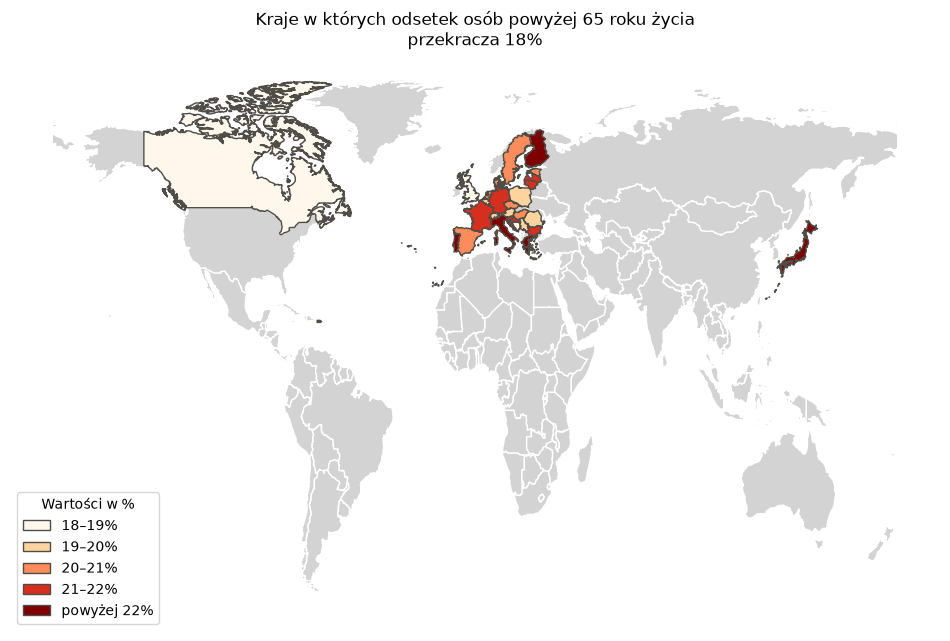

In [43]:
#Wizualizacja
#print(demo_18)


import matplotlib.pyplot as plt


granice = [18, 19, 20, 21, 22, 100]
etykiety = ["18–19%", "19–20%", "20–21%", "21–22%", "powyżej 22%"]

demo_18["legenda1"] = pd.cut(demo_18["ludnosc_65_percent"], bins=granice, labels=etykiety)

maps1 = demo.plot(color = "lightgrey", edgecolor = "white", figsize=(12,8))
demo_18.plot (ax = maps1, 
              column = "legenda1",
              categorical = True,
              cmap = "OrRd",
              edgecolor = "#4f4d47",
              legend = True,
              legend_kwds = {"title": "Wartości w %", "loc": "lower left"}
)
maps1.set_axis_off()
maps1.set_title("Kraje w których odsetek osób powyżej 65 roku życia\nprzekracza 18%")


In [67]:
#Dla warstwy z wulkanami stwórz podzbiór wulkanów znajdujących się w Stanach Zjednoczonych.
# Następnie wypisz wszystkie typy wulkanów występujące w tym podzbiorze oraz oblicz, jaki procent wszystkich wulkanów w USA stanowi każdy z typów



usa_wulkany = geojson_vulcan[geojson_vulcan["kraj"] == "Stany Zjednoczone"]

odsetek = (usa_wulkany["typ"].value_counts(normalize = True)*100)

print(odsetek.map("{:.1f} %".format).to_string())

typ
stratowulkan         51.2 %
tarczowy             11.9 %
podwodny             10.7 %
pole wulkaniczne      8.9 %
stożkowy              7.1 %
kopuła lawowa         3.6 %
maar                  3.0 %
kaldera               3.0 %
mieszane, złożone     0.6 %
